In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, roc_curve,
    classification_report, f1_score,
    matthews_corrcoef, fbeta_score
)

# SMOTE
from imblearn.over_sampling import SMOTE

# Classifiers
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
import lightgbm as lgb
from sklearn.neural_network import MLPClassifier

# AutoEncoder
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

print('✅ Semua library berhasil diimport.')

✅ Semua library berhasil diimport.


In [2]:
df = pd.read_csv('/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv')
print(f"Shape dataset: {df.shape}")
df.head()

Shape dataset: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Legitimate (0) : 284315 (99.827%)
Fraudulent (1) : 492 (0.173%)


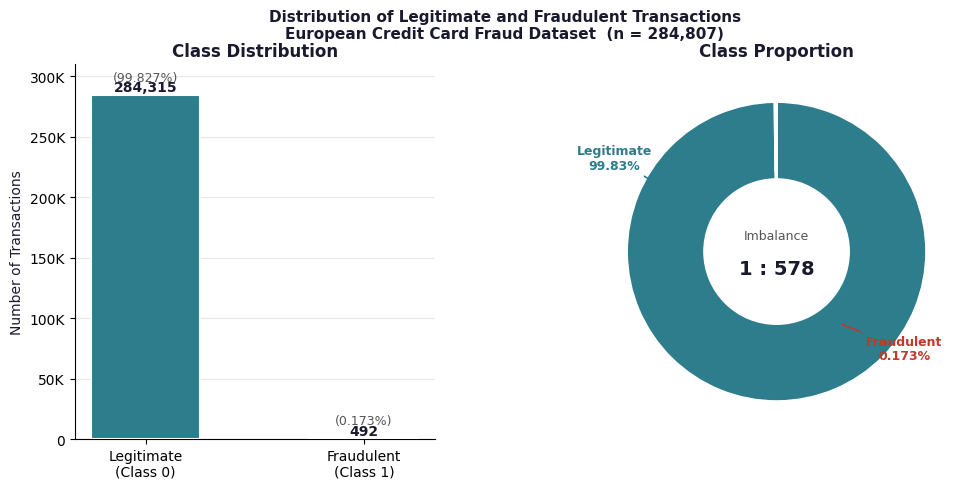

In [3]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# ── Data ──────────────────────────────────────────────────────────────
class_counts = df['Class'].value_counts()
n_legitimate = class_counts[0]
n_fraud      = class_counts[1]
total        = len(df)
pct_legit    = n_legitimate / total * 100
pct_fraud    = n_fraud      / total * 100

print(f"Legitimate (0) : {n_legitimate} ({pct_legit:.3f}%)")
print(f"Fraudulent (1) : {n_fraud} ({pct_fraud:.3f}%)")

# ── Color palette ──────────────────────────────────────────────────────
COL_LEGIT = '#2E7D8C'
COL_FRAUD = '#C0392B'
COL_BG    = '#FFFFFF'
COL_GRID  = '#E8E8E8'
COL_TEXT  = '#1A1A2E'
COL_SUB   = '#555555'

fig = plt.figure(figsize=(10, 5), facecolor=COL_BG)
fig.subplots_adjust(left=0.07, right=0.97, top=0.88, bottom=0.13, wspace=0.38)
gs  = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1, 1.1])

# Panel kiri — Bar chart
ax1 = fig.add_subplot(gs[0])
ax1.set_facecolor(COL_BG)
bars = ax1.bar(['Legitimate\n(Class 0)', 'Fraudulent\n(Class 1)'],
               [n_legitimate, n_fraud],
               color=[COL_LEGIT, COL_FRAUD],
               width=0.5, edgecolor='white', linewidth=1.5, zorder=3)
ax1.yaxis.grid(True, color=COL_GRID, linewidth=0.8, zorder=0)
ax1.set_axisbelow(True)
for bar, val, pct in zip(bars, [n_legitimate, n_fraud], [pct_legit, pct_fraud]):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 3000,
             f'{val:,}', ha='center', fontsize=10, fontweight='bold', color=COL_TEXT)
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 12000,
             f'({pct:.3f}%)', ha='center', fontsize=9, color=COL_SUB)
ax1.set_ylabel('Number of Transactions', fontsize=10, color=COL_TEXT)
ax1.set_ylim(0, 310000)
ax1.set_title('Class Distribution', fontsize=12, fontweight='bold', color=COL_TEXT)
ax1.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{int(x/1000)}K' if x >= 1000 else str(int(x))))
for spine in ['top', 'right']:
    ax1.spines[spine].set_visible(False)

# Panel kanan — Donut chart
ax2 = fig.add_subplot(gs[1])
ax2.set_facecolor(COL_BG)
ax2.pie([pct_legit, pct_fraud],
        colors=[COL_LEGIT, COL_FRAUD],
        explode=(0, 0.06), startangle=90,
        wedgeprops=dict(width=0.52, edgecolor='white', linewidth=2),
        counterclock=False)
ax2.text(0,  0.08, 'Imbalance', ha='center', fontsize=9,  color=COL_SUB)
ax2.text(0, -0.15, '1 : 578',   ha='center', fontsize=14, fontweight='bold', color=COL_TEXT)
ax2.annotate(f'Legitimate\n{pct_legit:.2f}%',
             xy=(-0.55, 0.30), xytext=(-1.08, 0.55), ha='center',
             fontsize=9, color=COL_LEGIT, fontweight='bold',
             arrowprops=dict(arrowstyle='-', color=COL_LEGIT, lw=1.2))
ax2.annotate(f'Fraudulent\n{pct_fraud:.3f}%',
             xy=(0.42, -0.48), xytext=(0.85, -0.72), ha='center',
             fontsize=9, color=COL_FRAUD, fontweight='bold',
             arrowprops=dict(arrowstyle='-', color=COL_FRAUD, lw=1.2))
ax2.set_title('Class Proportion', fontsize=12, fontweight='bold', color=COL_TEXT)

fig.suptitle(
    'Distribution of Legitimate and Fraudulent Transactions\n'
    'European Credit Card Fraud Dataset  (n = 284,807)',
    fontsize=11, fontweight='bold', color=COL_TEXT, y=0.99)

plt.savefig('class_distribution.png', dpi=300, bbox_inches='tight', facecolor=COL_BG)
plt.show()

In [4]:
# Handle missing values
if df.isnull().sum().max() > 0:
    df = df.fillna(df.mean())
    print("Missing values diisi dengan mean.")
else:
    print("Tidak ada missing values.")

X = df.drop(['Class', 'Time'], axis=1).values
y = df['Class'].values

print(f"Shape X : {X.shape}")
print(f"Shape y : {y.shape}")

Tidak ada missing values.
Shape X : (284807, 29)
Shape y : (284807,)


SPLIT

In [5]:
from sklearn.model_selection import train_test_split

X_train_full, X_test_final, y_train_full, y_test_final = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Train Set:", X_train_full.shape)
print("Test Set :", X_test_final.shape)
print(f"Fraud -> Train: {sum(y_train_full)} | Test: {sum(y_test_final)}")


Train Set: (227845, 29)
Test Set : (56962, 29)
Fraud -> Train: 394 | Test: 98


In [6]:
LATENT_DIM = 256   # dimensi latent space AutoEncoder

def build_autoencoder(input_dim):
    """AutoEncoder — sama untuk semua model & semua fold."""
    inp     = Input(shape=(input_dim,))
    enc     = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(inp)
    latent  = Dense(LATENT_DIM, activation='relu', kernel_regularizer=l2(0.001))(enc)
    dec     = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(latent)
    out     = Dense(input_dim, activation='linear')(dec)

    ae      = Model(inputs=inp, outputs=out)
    encoder = Model(inputs=inp, outputs=latent)
    # mse lebih tepat dari binary_crossentropy untuk data StandardScaler
    # (nilainya kontinu & bisa negatif, bukan probabilitas 0-1)
    ae.compile(optimizer=Adam(learning_rate=0.0001), loss='mse')
    return ae, encoder


def extract_hybrid_features(ae, encoder, X_tr, X_te):
    """Gabung: Original Features + Latent Space + MSE Reconstruction Error."""
    mse_tr  = np.mean(np.power(X_tr - ae.predict(X_tr, verbose=0), 2), axis=1, keepdims=True)
    mse_te  = np.mean(np.power(X_te - ae.predict(X_te, verbose=0), 2), axis=1, keepdims=True)
    lat_tr  = encoder.predict(X_tr, verbose=0)
    lat_te  = encoder.predict(X_te, verbose=0)
    return np.hstack((X_tr, lat_tr, mse_tr)), np.hstack((X_te, lat_te, mse_te))


SMOTE_SAMPLING_STRATEGY = 0.25  # rasio minoritas:majoritas setelah resampling
                                 # 0.25 -> fraud:normal jadi ~20:80
                                 # Nilai ini dipilih berdasarkan SMOTE Sensitivity Analysis
                                 # (lihat cell sensitivity analysis di bawah)

def apply_smote(X_hybrid_train, y_train, fold_num, sampling_strategy=SMOTE_SAMPLING_STRATEGY):
    """
    SMOTE diterapkan HANYA pada X_train_hybrid (Pilihan B).
    X_test tidak disentuh — tetap distribusi asli.

    sampling_strategy : rasio jumlah sampel minoritas (fraud) dibagi
    majoritas (normal) SETELAH resampling. 1.0 = balance penuh 50:50.
    0.10 = fraud dibuat jadi 10% dari normal (rasio ~80:20), supaya model
    tidak terlalu "berani" menandai fraud (mengurangi false positive).
    """
    sm = SMOTE(random_state=42, k_neighbors=5, sampling_strategy=sampling_strategy)
    X_res, y_res = sm.fit_resample(X_hybrid_train, y_train)
    fraud_before  = int(np.sum(y_train == 1))
    fraud_after   = int(np.sum(y_res == 1))
    normal_after  = int(np.sum(y_res == 0))
    print(f'[Fold {fold_num}] SMOTE (sampling_strategy={sampling_strategy}): '
          f'fraud {fraud_before} → {fraud_after} | normal tetap {normal_after} | '
          f'total train {len(y_train)} → {len(y_res)}')
    return X_res, y_res


RECALL_WEIGHT = 0.80
def find_optimal_threshold(model, X_val, y_val, weight=RECALL_WEIGHT):
    prob = model.predict_proba(X_val)[:,1]
    fpr, tpr, thresholds = roc_curve(y_val, prob)

    j_scores = (weight * tpr) - ((1 - weight) * fpr)
    best_t = thresholds[np.argmax(j_scores)]

    return best_t


SOTA_ACC    = 0.95130
SOTA_RECALL = 0.91176
WEIGHT_CANDIDATES = [0.60, 0.65, 0.70, 0.75, 0.80]

def find_thresholds_multi_weight(model, X_val, y_val, weights=WEIGHT_CANDIDATES):
    """
    Hitung threshold Youden's J untuk BEBERAPA weight sekaligus, dari
    SATU kali predict_proba + SATU kali roc_curve saja (efisien, model
    tidak perlu di-retrain per weight).
    Return: dict {weight: threshold}
    """
    prob = model.predict_proba(X_val)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_val, prob)
    out = {}
    for w in weights:
        j = (w * tpr) - ((1 - w) * fpr)
        out[w] = thresholds[np.argmax(j)]
    return out


print('Fungsi helper siap.')


Fungsi helper siap.


SPLIT DATA 80/20

In [7]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

MODEL_NAMES = ['AE + XGBoost', 'AE + Random Forest', 'AE + CatBoost', 'AE + LightGBM', 'AE + MLP']

# results[model][weight] = {'acc':[], 'dr':[]}  -- nested per kandidat weight
# auc_results[model] = []  -- AUC tidak tergantung threshold/weight, jadi flat saja
results = {m: {w: {'acc': [], 'dr': [], 'f1': []} for w in WEIGHT_CANDIDATES} for m in MODEL_NAMES}
auc_results = {m: [] for m in MODEL_NAMES}

# fold_thresholds[model][weight] = [list threshold per fold]
fold_thresholds = {m: {w: [] for w in WEIGHT_CANDIDATES} for m in MODEL_NAMES}

last_fold = {}

for fold_num, (train_idx, val_idx) in enumerate(
    skf.split(X_train_full, y_train_full),
    start=1
):
    print(f'\n{"="*55}')
    print(f'                   FOLD {fold_num} / 5')
    print(f'{"="*55}')

    X_train_raw = X_train_full[train_idx]
    X_val_raw   = X_train_full[val_idx]

    y_train = y_train_full[train_idx]
    y_val   = y_train_full[val_idx]

    # ── Scaling ──────────────────────────────────────────────
    scaler  = StandardScaler()
    X_train = scaler.fit_transform(X_train_raw)
    X_val   = scaler.transform(X_val_raw)

    print(f'Train: {X_train.shape} | Validation: {X_val.shape}')
    print(f'Fraud di train: {sum(y_train)} | Fraud di validation: {sum(y_val)}')

    # ── AutoEncoder ───────────────────────────────────────────
    X_train_normal = X_train[y_train == 0]
    ae, encoder = build_autoencoder(X_train.shape[1])
    ae.fit(
        X_train_normal, X_train_normal,
        epochs=50, batch_size=64, validation_split=0.1,
        callbacks=[EarlyStopping(monitor='val_loss', patience=5,
                                 restore_best_weights=True)],
        verbose=0
    )
    print(f'[Fold {fold_num}] AutoEncoder selesai (training dari data normal saja).')

    # ── Ekstraksi Fitur Hybrid ────────────────────────────────
    X_train_hybrid, X_val_hybrid = extract_hybrid_features(
        ae, encoder, X_train, X_val
    )
    print(f'[Fold {fold_num}] Dimensi hybrid: {X_train_hybrid.shape[1]} fitur')

    # ── Split internal: Fit (training model) vs Threshold-tuning ──
    X_fit_hybrid, X_thresh_hybrid, y_fit, y_thresh = train_test_split(
        X_train_hybrid, y_train,
        test_size=0.2, stratify=y_train, random_state=42
    )
    print(f'[Fold {fold_num}] Split internal -> Fit: {X_fit_hybrid.shape[0]} | '
          f'Threshold-tuning: {X_thresh_hybrid.shape[0]} | Val (evaluasi): {X_val_hybrid.shape[0]}')

    # ── SMOTE ─────────────────────────────────────
    X_tr, y_tr = apply_smote(
        X_fit_hybrid,
        y_fit,
        fold_num
    )

    models_this_fold = {}

    # ════════════════════════════════════════
    # MODEL 1 — AE + XGBoost
    # ════════════════════════════════════════
    m1 = xgb.XGBClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=6,
        min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
        random_state=42, eval_metric='auc', verbosity=0
    )
    m1.fit(X_tr, y_tr)
    models_this_fold['AE + XGBoost'] = m1

    # ════════════════════════════════════════
    # MODEL 2 — AE + Random Forest
    # ════════════════════════════════════════
    m2 = RandomForestClassifier(
        n_estimators=200, max_depth=None,
        n_jobs=-1, random_state=42
    )
    m2.fit(X_tr, y_tr)
    models_this_fold['AE + Random Forest'] = m2

    # ════════════════════════════════════════
    # MODEL 3 — AE + Catboost
    # ════════════════════════════════════════
    m3 = CatBoostClassifier(
        iterations=200,
        learning_rate=0.05,
        depth=6,
        random_state=42,
        verbose=0
    )
    m3.fit(X_tr, y_tr)
    models_this_fold['AE + CatBoost'] = m3

    # ════════════════════════════════════════
    # MODEL 4 — AE + LightGBM
    # ════════════════════════════════════════
    m4 = lgb.LGBMClassifier(
        n_estimators=200, learning_rate=0.05,
        max_depth=6, subsample=0.8, colsample_bytree=0.8,
        is_unbalance=False,
        random_state=42, verbose=-1
    )
    m4.fit(X_tr, y_tr)
    models_this_fold['AE + LightGBM'] = m4

    # ════════════════════════════════════════
    # MODEL 5 — AE + MLP
    # ════════════════════════════════════════
    m5 = MLPClassifier(
        hidden_layer_sizes=(256, 128, 64),
        activation='relu', solver='adam',
        learning_rate_init=0.001, max_iter=200,
        early_stopping=True, validation_fraction=0.1,
        random_state=42
    )
    m5.fit(X_tr, y_tr)
    models_this_fold['AE + MLP'] = m5

    # ── Untuk tiap model: hitung threshold di SEMUA weight kandidat,
    #    lalu evaluasi tiap weight ke val fold ini (tanpa retrain) ──
    fold_preds_for_last = {}
    for name, model in models_this_fold.items():
        thresh_dict = find_thresholds_multi_weight(model, X_thresh_hybrid, y_thresh, WEIGHT_CANDIDATES)
        prob_val = model.predict_proba(X_val_hybrid)[:, 1]
        auc_results[name].append(roc_auc_score(y_val, prob_val) * 100)

        for w in WEIGHT_CANDIDATES:
            t = thresh_dict[w]
            pred = (prob_val >= t).astype(int)
            results[name][w]['acc'].append(accuracy_score(y_val, pred) * 100)
            results[name][w]['dr'].append(recall_score(y_val, pred, zero_division=0) * 100)
            results[name][w]['f1'].append(f1_score(y_val, pred, zero_division=0) * 100)
            fold_thresholds[name][w].append(t)

        # simpan prediksi pakai weight default (0.80) hanya buat referensi last_fold
        default_t = thresh_dict[RECALL_WEIGHT]
        fold_preds_for_last[name] = (y_val, (prob_val >= default_t).astype(int), prob_val)

        print(f'[Fold {fold_num}] {name:<20} AUC:{auc_results[name][-1]:.2f}% | '
              + ' | '.join(f'w={w}: Acc={results[name][w]["acc"][-1]:.1f}/DR={results[name][w]["dr"][-1]:.1f}'
                           for w in WEIGHT_CANDIDATES))

    if fold_num == 5:
        last_fold = fold_preds_for_last

print('\n' + '='*55)
print('Training & evaluasi selesai untuk semua fold.')
print('='*55)



                   FOLD 1 / 5
Train: (182276, 29) | Validation: (45569, 29)
Fraud di train: 316 | Fraud di validation: 78


I0000 00:00:1786784835.573386      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786784835.577384      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1786784839.799712      75 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


[Fold 1] AutoEncoder selesai (training dari data normal saja).
[Fold 1] Dimensi hybrid: 286 fitur
[Fold 1] Split internal -> Fit: 145820 | Threshold-tuning: 36456 | Val (evaluasi): 45569
[Fold 1] SMOTE (sampling_strategy=0.25): fraud 253 → 36391 | normal tetap 145567 | total train 145820 → 181958
[Fold 1] AE + XGBoost         AUC:98.90% | w=0.6: Acc=93.1/DR=96.2 | w=0.65: Acc=90.3/DR=97.4 | w=0.7: Acc=90.3/DR=97.4 | w=0.75: Acc=90.3/DR=97.4 | w=0.8: Acc=90.3/DR=97.4
[Fold 1] AE + Random Forest   AUC:98.87% | w=0.6: Acc=98.1/DR=96.2 | w=0.65: Acc=98.1/DR=96.2 | w=0.7: Acc=98.1/DR=96.2 | w=0.75: Acc=98.1/DR=96.2 | w=0.8: Acc=77.5/DR=98.7
[Fold 1] AE + CatBoost        AUC:99.10% | w=0.6: Acc=95.5/DR=97.4 | w=0.65: Acc=93.1/DR=97.4 | w=0.7: Acc=93.1/DR=97.4 | w=0.75: Acc=93.1/DR=97.4 | w=0.8: Acc=93.1/DR=97.4
[Fold 1] AE + LightGBM        AUC:98.99% | w=0.6: Acc=96.1/DR=96.2 | w=0.65: Acc=96.1/DR=96.2 | w=0.7: Acc=96.1/DR=96.2 | w=0.75: Acc=96.1/DR=96.2 | w=0.8: Acc=79.4/DR=98.7
[Fold 1] A

In [8]:
print("\n" + "="*70)
print("PERBANDINGAN WEIGHT (rata-rata 5-fold CV) -- dari data TRAIN saja")
print("="*70)

best_weight_per_model = {}

for name in MODEL_NAMES:
    print(f"\n{name}  (AUC rata-rata: {np.mean(auc_results[name]):.2f}%)")
    print(f"{'Weight':<10}{'Acc (CV avg)':<16}{'Recall (CV avg)':<18}{'F1 (CV avg)':<14}")

    for w in WEIGHT_CANDIDATES:
        acc = np.mean(results[name][w]['acc'])
        dr  = np.mean(results[name][w]['dr'])
        f1  = np.mean(results[name][w]['f1'])
        flag = '(vs SOTA: *)' if (acc/100 >= SOTA_ACC and dr/100 >= SOTA_RECALL) else ''
        print(f"{w:<10}{acc:<16.2f}{dr:<18.2f}{f1:<14.2f}{flag}")

    # Kriteria pemilihan: F1-score CV rata-rata TERTINGGI -- metrik yang
    # berdiri sendiri (tidak menyebut/mengacu ke angka SOTA sama sekali),
    # supaya pemilihan weight tidak "diarahkan" untuk mengalahkan SOTA.
    best_w = max(WEIGHT_CANDIDATES, key=lambda w: np.mean(results[name][w]['f1']))
    best_weight_per_model[name] = best_w
    print(f"--> Weight terpilih untuk {name}: {best_w}  "
          f"(berdasarkan F1-score CV tertinggi: {np.mean(results[name][best_w]['f1']):.2f}%)")

print(f"\n('(vs SOTA: *)' di atas cuma INFORMASI tambahan -- BUKAN kriteria "
      f"pemilihan. Weight dipilih murni berdasarkan F1-score CV tertinggi.)")
print(f"\nWeight terpilih per model: {best_weight_per_model}")



PERBANDINGAN WEIGHT (rata-rata 5-fold CV) -- dari data TRAIN saja

AE + XGBoost  (AUC rata-rata: 98.33%)
Weight    Acc (CV avg)    Recall (CV avg)   F1 (CV avg)   
0.6       95.46           92.40             10.77         (vs SOTA: *)
0.65      93.76           93.92             8.77          
0.7       92.52           94.42             4.82          
0.75      91.70           94.42             4.62          
0.8       88.69           94.68             4.03          
--> Weight terpilih untuk AE + XGBoost: 0.6  (berdasarkan F1-score CV tertinggi: 10.77%)

AE + Random Forest  (AUC rata-rata: 97.41%)
Weight    Acc (CV avg)    Recall (CV avg)   F1 (CV avg)   
0.6       97.29           92.90             13.79         (vs SOTA: *)
0.65      96.28           93.15             11.12         (vs SOTA: *)
0.7       96.28           93.15             11.12         (vs SOTA: *)
0.75      93.95           94.17             6.90          
0.8       88.63           94.93             3.49          
--> 

In [9]:
# best_thresholds = rata-rata threshold dari 5 fold, MASING-MASING DIAMBIL
# DARI WEIGHT YANG SUDAH TERPILIH (paling seimbang) untuk model itu --
# bukan dari satu weight global yang sama untuk semua model.
best_thresholds = {
    name: np.mean(fold_thresholds[name][best_weight_per_model[name]])
    for name in MODEL_NAMES
}

print("Threshold rata-rata (dari 5 fold, sesuai weight terpilih tiap model):")
for name in MODEL_NAMES:
    w = best_weight_per_model[name]
    per_fold = ", ".join(f"{x:.3f}" for x in fold_thresholds[name][w])
    print(f"  {name:<20} (weight={w}): {best_thresholds[name]:.4f}   (per-fold: {per_fold})")


Threshold rata-rata (dari 5 fold, sesuai weight terpilih tiap model):
  AE + XGBoost         (weight=0.6): 0.0111   (per-fold: 0.004, 0.005, 0.011, 0.034, 0.001)
  AE + Random Forest   (weight=0.6): 0.0350   (per-fold: 0.040, 0.050, 0.020, 0.045, 0.020)
  AE + CatBoost        (weight=0.6): 0.0236   (per-fold: 0.017, 0.047, 0.012, 0.033, 0.009)
  AE + LightGBM        (weight=0.6): 0.0026   (per-fold: 0.006, 0.001, 0.001, 0.002, 0.001)
  AE + MLP             (weight=0.6): 0.0000   (per-fold: 0.000, 0.000, 0.000, 0.000, 0.000)


In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_full)
X_test_scaled  = scaler.transform(X_test_final)


In [11]:
X_train_normal = X_train_scaled[y_train_full == 0]

ae, encoder = build_autoencoder(X_train_scaled.shape[1])

ae.fit(
    X_train_normal,
    X_train_normal,
    epochs=50,
    batch_size=64,
    validation_split=0.1,
    callbacks=[
        EarlyStopping(
            monitor='val_loss',
            patience=5,
            restore_best_weights=True
        )
    ],
    verbose=1
)

Epoch 1/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - loss: 0.4526 - val_loss: 0.2023
Epoch 2/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.1374 - val_loss: 0.0947
Epoch 3/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.0804 - val_loss: 0.0688
Epoch 4/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.0657 - val_loss: 0.0597
Epoch 5/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.0583 - val_loss: 0.0544
Epoch 6/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.0541 - val_loss: 0.0531
Epoch 7/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.0513 - val_loss: 0.0484
Epoch 8/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.0488 - val_loss: 0.0471
Epoch 9/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.0462 - val_loss: 0.0475
Epoch 10/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.0447 - val_loss: 0.0429
Epoch 11/50
3199/3199 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.0434 - val_loss: 0.0413
Epoch 12/50
3199/3199 ━━━━━━━

In [12]:
X_train_hybrid, X_test_hybrid = extract_hybrid_features(
    ae,
    encoder,
    X_train_scaled,
    X_test_scaled
)


In [13]:
X_train_smote, y_train_smote = apply_smote(
    X_train_hybrid,
    y_train_full,
    fold_num=0
)

[Fold 0] SMOTE (sampling_strategy=0.25): fraud 394 → 56862 | normal tetap 227451 | total train 227845 → 284313


In [14]:
m1 = xgb.XGBClassifier(
    objective='binary:logistic',
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=5,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='auc',
    random_state=42,
    verbosity=0
)
m1.fit(X_train_smote, y_train_smote)

m2 = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    n_jobs=-1,
    random_state=42
)
m2.fit(X_train_smote, y_train_smote)

m3 = CatBoostClassifier(
    iterations=200,
    learning_rate=0.05,
    depth=6,
    random_state=42,
    verbose=0
)
m3.fit(X_train_smote, y_train_smote)

m4 = lgb.LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    is_unbalance=False,
    random_state=42,
    verbose=-1
)
m4.fit(X_train_smote, y_train_smote)

m5 = MLPClassifier(
    hidden_layer_sizes=(256,128,64),
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    max_iter=200,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)
m5.fit(X_train_smote, y_train_smote)

MLPClassifier(early_stopping=True, hidden_layer_sizes=(256, 128, 64),
              random_state=42)

In [15]:
final_models = {
    "AE + XGBoost": m1,
    "AE + Random Forest": m2,
    "AE + CatBoost": m3,
    "AE + LightGBM": m4,
    "AE + MLP": m5
}

In [16]:
from sklearn.metrics import classification_report

all_predictions = {}

print("\nFINAL HOLD-OUT TEST RESULTS")
print("="*60)

for name, model in final_models.items():

    prob = model.predict_proba(X_test_hybrid)[:,1]

    threshold = best_thresholds[name]   # rata-rata threshold dari 5 fold CV

    pred = (prob >= threshold).astype(int)

    # simpan hasil prediksi (dict, dipakai cell confusion matrix/ROC/PR di bawah)
    all_predictions[name] = {'pred': pred, 'prob': prob}

    acc = accuracy_score(y_test_final, pred)*100
    dr  = recall_score(y_test_final, pred)*100
    auc = roc_auc_score(y_test_final, prob)*100

    print(
        f"{name:<20}"
        f" Acc={acc:.2f}%"
        f" | DR={dr:.2f}%"
        f" | AUC={auc:.2f}%"
    )



FINAL HOLD-OUT TEST RESULTS
AE + XGBoost         Acc=96.47% | DR=93.88% | AUC=98.16%
AE + Random Forest   Acc=97.74% | DR=91.84% | AUC=97.13%
AE + CatBoost        Acc=95.04% | DR=93.88% | AUC=97.37%
AE + LightGBM        Acc=87.93% | DR=94.90% | AUC=97.94%
AE + MLP             Acc=98.00% | DR=88.78% | AUC=97.37%


In [17]:
# ── Bootstrap 95% Confidence Interval ──────────────────────────────
# Resampling Test set (DENGAN pengembalian) sebanyak N_BOOTSTRAP kali,
# lalu hitung ulang Acc/DR/AUC dari prediksi yang SUDAH ADA (tanpa
# retrain apapun). Ini menunjukkan seberapa STABIL angka hasil test kita
# -- bukan cuma satu titik angka, tapi rentang yang masuk akal.
#
# PENTING: ini cuma analisis statistik tambahan untuk laporan, BUKAN
# dipakai untuk memilih threshold/weight apapun -- jadi tidak melanggar
# aturan anti-leakage yang sudah kita pegang sejak awal.

N_BOOTSTRAP = 1000
rng = np.random.RandomState(42)
n_test = len(y_test_final)

bootstrap_results = {name: {'acc': [], 'dr': [], 'auc': []} for name in all_predictions}

for name, data in all_predictions.items():
    pred = data['pred']
    prob = data['prob']

    for _ in range(N_BOOTSTRAP):
        idx = rng.randint(0, n_test, n_test)   # resample dengan pengembalian
        y_bs    = y_test_final[idx]
        pred_bs = pred[idx]
        prob_bs = prob[idx]

        if len(np.unique(y_bs)) < 2:
            continue   # skip kalau kebetulan resample tidak punya 2 kelas (jarang terjadi)

        bootstrap_results[name]['acc'].append(accuracy_score(y_bs, pred_bs) * 100)
        bootstrap_results[name]['dr'].append(recall_score(y_bs, pred_bs, zero_division=0) * 100)
        bootstrap_results[name]['auc'].append(roc_auc_score(y_bs, prob_bs) * 100)

print(f"BOOTSTRAP 95% CONFIDENCE INTERVAL  (n={N_BOOTSTRAP} resample dari Test set)")
print("="*78)

ci_summary = {}
for name in all_predictions:
    acc_arr = np.array(bootstrap_results[name]['acc'])
    dr_arr  = np.array(bootstrap_results[name]['dr'])
    auc_arr = np.array(bootstrap_results[name]['auc'])

    acc_ci = np.percentile(acc_arr, [2.5, 97.5])
    dr_ci  = np.percentile(dr_arr,  [2.5, 97.5])
    auc_ci = np.percentile(auc_arr, [2.5, 97.5])
    ci_summary[name] = {'acc': (acc_arr.mean(), acc_ci), 'dr': (dr_arr.mean(), dr_ci), 'auc': (auc_arr.mean(), auc_ci)}

    # cek apakah BATAS BAWAH CI masih melebihi SOTA -> klaim "menang" jadi kuat secara statistik
    acc_beats_sota_robustly = acc_ci[0] >= SOTA_ACC * 100
    dr_beats_sota_robustly  = dr_ci[0]  >= SOTA_RECALL * 100

    print(f"\n{name}")
    print(f"  Acc: {acc_arr.mean():6.2f}%   95% CI: [{acc_ci[0]:6.2f}% , {acc_ci[1]:6.2f}%]"
          f"   {'(robust > SOTA)' if acc_beats_sota_robustly else ''}")
    print(f"  DR : {dr_arr.mean():6.2f}%   95% CI: [{dr_ci[0]:6.2f}% , {dr_ci[1]:6.2f}%]"
          f"   {'(robust > SOTA)' if dr_beats_sota_robustly else ''}")
    print(f"  AUC: {auc_arr.mean():6.2f}%   95% CI: [{auc_ci[0]:6.2f}% , {auc_ci[1]:6.2f}%]")

print(f"\n('robust > SOTA' artinya BATAS BAWAH dari 95% CI masih di atas angka SOTA"
      f" -- jadi unggulnya bukan kebetulan dari satu sampel test, tapi konsisten secara statistik.)")


BOOTSTRAP 95% CONFIDENCE INTERVAL  (n=1000 resample dari Test set)

AE + XGBoost
  Acc:  96.47%   95% CI: [ 96.33% ,  96.62%]   (robust > SOTA)
  DR :  94.02%   95% CI: [ 89.19% ,  98.10%]   
  AUC:  98.21%   95% CI: [ 96.27% ,  99.62%]

AE + Random Forest
  Acc:  97.74%   95% CI: [ 97.62% ,  97.87%]   (robust > SOTA)
  DR :  91.94%   95% CI: [ 86.17% ,  97.03%]   
  AUC:  97.18%   95% CI: [ 94.43% ,  99.40%]

AE + CatBoost
  Acc:  95.04%   95% CI: [ 94.86% ,  95.21%]   
  DR :  93.76%   95% CI: [ 88.51% ,  98.10%]   
  AUC:  97.30%   95% CI: [ 94.73% ,  99.31%]

AE + LightGBM
  Acc:  87.94%   95% CI: [ 87.66% ,  88.19%]   
  DR :  94.87%   95% CI: [ 90.26% ,  98.91%]   
  AUC:  97.94%   95% CI: [ 96.04% ,  99.58%]

AE + MLP
  Acc:  98.00%   95% CI: [ 97.88% ,  98.11%]   (robust > SOTA)
  DR :  88.73%   95% CI: [ 82.22% ,  94.44%]   
  AUC:  97.37%   95% CI: [ 95.07% ,  99.19%]

('robust > SOTA' artinya BATAS BAWAH dari 95% CI masih di atas angka SOTA -- jadi unggulnya bukan kebetulan 

### SMOTE Sampling Strategy Sensitivity Analysis

In [18]:
# ══════════════════════════════════════════════════════════════════════
# SMOTE SAMPLING STRATEGY SENSITIVITY ANALYSIS
# Tujuan : Menentukan nilai sampling_strategy SMOTE yang optimal
#          berdasarkan F1-Score rata-rata 3-fold CV.
# Kandidat: [0.10, 0.25, 0.50, 0.75, 1.00]
#
# ANTI-LEAKAGE:
#   - AE ditraining ulang dari nol untuk setiap fold (bukan reuse)
#   - Scaler di-fit hanya dari training fold
#   - SMOTE hanya di Fit Set (80% dari training fold)
#   - Threshold tuning di Threshold-Tuning Set (20% dari training fold)
#   - Evaluasi di val fold yang tidak pernah dilihat model
#   - X_test_final TIDAK pernah disentuh di cell ini
#
# CATATAN: Cell ini BERDIRI SENDIRI — tidak membutuhkan hasil
#          dari main CV loop di atas. Cukup run cell imports (cell 2),
#          cell load data (cell 3+4+5), cell split (cell 7),
#          dan cell helper functions (cell 8), lalu run cell ini.
# ══════════════════════════════════════════════════════════════════════

import gc
import tensorflow as tf

SMOTE_CANDIDATES  = [0.10, 0.25, 0.50, 0.75, 1.00]
N_FOLDS_SENS      = 3          # 3-fold untuk efisiensi waktu
FIXED_WEIGHT      = 0.75       # weight Youden's J tetap untuk semua kandidat
                               # (tujuan: isolasi efek SMOTE, bukan threshold)
MODEL_NAMES_SENS  = [
    'AE + XGBoost', 'AE + Random Forest', 'AE + CatBoost',
    'AE + LightGBM', 'AE + MLP'
]

# Inisialisasi container hasil
smote_sens_results = {
    s: {name: {'f1': [], 'acc': [], 'dr': []} for name in MODEL_NAMES_SENS}
    for s in SMOTE_CANDIDATES
}

skf_sens = StratifiedKFold(n_splits=N_FOLDS_SENS, shuffle=True, random_state=42)

for smote_val in SMOTE_CANDIDATES:
    print(f"\n{'='*65}")
    print(f"  SMOTE sampling_strategy = {smote_val}  "
          f"(fraud:normal ≈ {int(smote_val*100)}:{100} setelah resampling)")
    print(f"{'='*65}")

    for fold_num, (train_idx, val_idx) in enumerate(
        skf_sens.split(X_train_full, y_train_full), start=1
    ):
        # ── 1. Split fold ──────────────────────────────────────────────
        X_fold_train_raw = X_train_full[train_idx]
        X_fold_val_raw   = X_train_full[val_idx]
        y_fold_train     = y_train_full[train_idx]
        y_fold_val       = y_train_full[val_idx]

        # ── 2. Scaling (fit HANYA dari training fold) ──────────────────
        scaler_sens = StandardScaler()
        X_fold_train_sc = scaler_sens.fit_transform(X_fold_train_raw)
        X_fold_val_sc   = scaler_sens.transform(X_fold_val_raw)

        # ── 3. AutoEncoder (ditraining ulang per fold per strategy) ───
        X_normal_sens = X_fold_train_sc[y_fold_train == 0]
        ae_sens, encoder_sens = build_autoencoder(X_fold_train_sc.shape[1])
        ae_sens.fit(
            X_normal_sens, X_normal_sens,
            epochs=50, batch_size=64, validation_split=0.1,
            callbacks=[EarlyStopping(monitor='val_loss', patience=5,
                                     restore_best_weights=True)],
            verbose=0
        )

        # ── 4. Hybrid features ─────────────────────────────────────────
        X_fold_train_hyb, X_fold_val_hyb = extract_hybrid_features(
            ae_sens, encoder_sens, X_fold_train_sc, X_fold_val_sc
        )

        # ── 5. Internal split: Fit Set / Threshold-Tuning Set ──────────
        X_fit_s, X_thresh_s, y_fit_s, y_thresh_s = train_test_split(
            X_fold_train_hyb, y_fold_train,
            test_size=0.20, stratify=y_fold_train, random_state=42
        )

        # ── 6. SMOTE hanya di Fit Set ──────────────────────────────────
        X_tr_s, y_tr_s = apply_smote(
            X_fit_s, y_fit_s, fold_num, sampling_strategy=smote_val
        )

        # ── 7. Train semua classifier & evaluasi ke val fold ───────────
        classifiers_sens = {
            'AE + XGBoost': xgb.XGBClassifier(
                n_estimators=200, learning_rate=0.05, max_depth=6,
                min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
                random_state=42, eval_metric='auc', verbosity=0
            ),
            'AE + Random Forest': RandomForestClassifier(
                n_estimators=200, n_jobs=-1, random_state=42
            ),
            'AE + CatBoost': CatBoostClassifier(
                iterations=200, learning_rate=0.05, depth=6,
                random_state=42, verbose=0
            ),
            'AE + LightGBM': lgb.LGBMClassifier(
                n_estimators=200, learning_rate=0.05, max_depth=6,
                subsample=0.8, colsample_bytree=0.8,
                is_unbalance=False, random_state=42, verbose=-1
            ),
            'AE + MLP': MLPClassifier(
                hidden_layer_sizes=(256, 128, 64), activation='relu',
                solver='adam', learning_rate_init=0.001, max_iter=200,
                early_stopping=True, validation_fraction=0.1,
                random_state=42
            ),
        }

        for name, clf in classifiers_sens.items():
            clf.fit(X_tr_s, y_tr_s)

            # Threshold dari Threshold-Tuning Set (bukan val fold!)
            thresh_s = find_optimal_threshold(
                clf, X_thresh_s, y_thresh_s, weight=FIXED_WEIGHT
            )

            # Evaluasi ke val fold
            prob_val  = clf.predict_proba(X_fold_val_hyb)[:, 1]
            pred_val  = (prob_val >= thresh_s).astype(int)

            smote_sens_results[smote_val][name]['f1'].append(
                f1_score(y_fold_val, pred_val, zero_division=0) * 100
            )
            smote_sens_results[smote_val][name]['acc'].append(
                accuracy_score(y_fold_val, pred_val) * 100
            )
            smote_sens_results[smote_val][name]['dr'].append(
                recall_score(y_fold_val, pred_val, zero_division=0) * 100
            )

        print(f"  [strategy={smote_val}] Fold {fold_num}/{N_FOLDS_SENS} selesai")

        # Bersihkan memori TensorFlow setelah tiap fold
        del ae_sens, encoder_sens
        tf.keras.backend.clear_session()
        gc.collect()

print(f"\n{'='*65}")
print("SMOTE Sensitivity Analysis selesai untuk semua kandidat.")
print(f"{'='*65}")



  SMOTE sampling_strategy = 0.1  (fraud:normal ≈ 10:100 setelah resampling)
[Fold 1] SMOTE (sampling_strategy=0.1): fraud 210 → 12130 | normal tetap 121306 | total train 121516 → 133436
  [strategy=0.1] Fold 1/3 selesai
[Fold 2] SMOTE (sampling_strategy=0.1): fraud 210 → 12130 | normal tetap 121307 | total train 121517 → 133437
  [strategy=0.1] Fold 2/3 selesai
[Fold 3] SMOTE (sampling_strategy=0.1): fraud 210 → 12130 | normal tetap 121307 | total train 121517 → 133437
  [strategy=0.1] Fold 3/3 selesai

  SMOTE sampling_strategy = 0.25  (fraud:normal ≈ 25:100 setelah resampling)
[Fold 1] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121306 | total train 121516 → 151632
  [strategy=0.25] Fold 1/3 selesai
[Fold 2] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121307 | total train 121517 → 151633
  [strategy=0.25] Fold 2/3 selesai
[Fold 3] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121307 | total train 121517 → 151633
  [strateg


SMOTE SAMPLING STRATEGY SENSITIVITY ANALYSIS
(Rata-rata 3-fold CV | Fixed weight=0.75)

AE + XGBoost
          Acc (%)  Recall (%)  F1 (%)
Strategy                             
0.10        93.10       93.40    6.15
0.25        93.09       93.40    4.81
0.50        90.67       94.41    3.40
0.75        89.32       93.92    7.61
1.00        87.36       95.43    2.63
  --> Best sampling_strategy (F1): 0.75

AE + Random Forest
          Acc (%)  Recall (%)  F1 (%)
Strategy                             
0.10        92.85       94.16    4.50
0.25        94.92       92.13    8.95
0.50        88.20       94.16    3.21
0.75        87.17       95.94    2.87
1.00        95.68       92.88    7.15
  --> Best sampling_strategy (F1): 0.25

AE + CatBoost
          Acc (%)  Recall (%)  F1 (%)
Strategy                             
0.10        91.17       93.39    5.41
0.25        94.45       91.63   12.03
0.50        91.50       93.40    4.31
0.75        87.66       93.67    7.66
1.00        87.37      

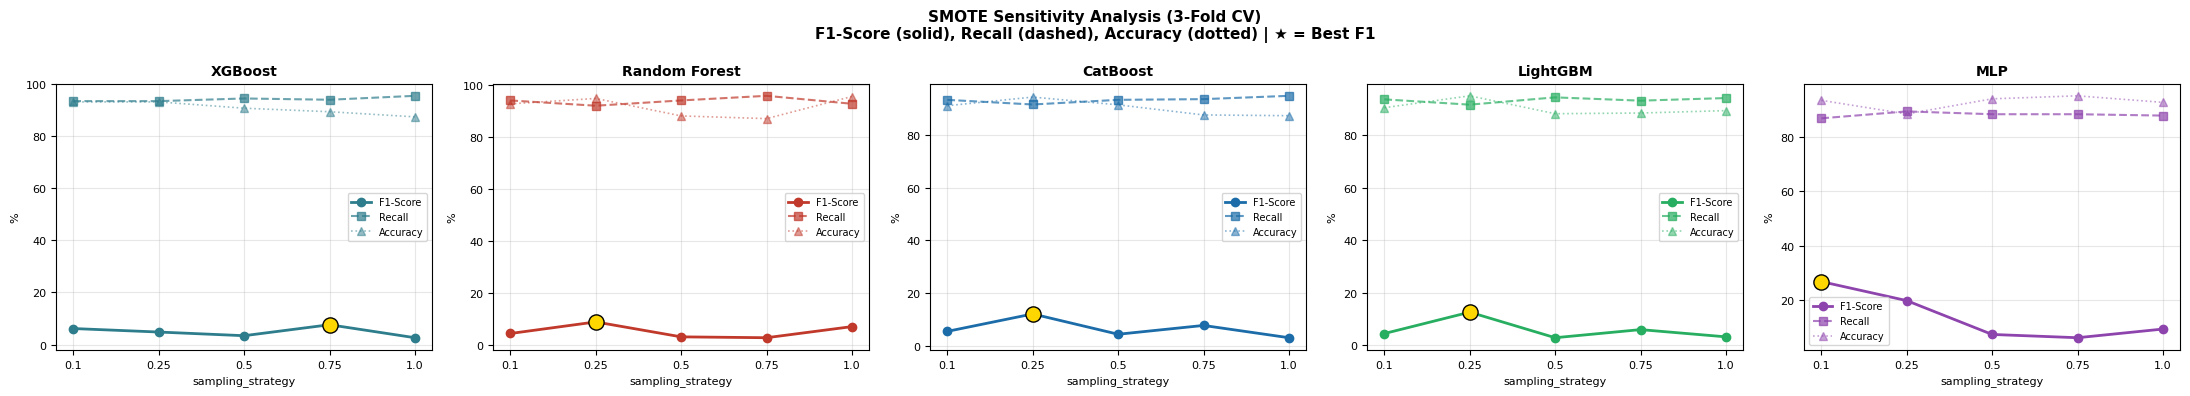


Grafik tersimpan sebagai smote_sensitivity.png


In [19]:
# ── Tabel & Visualisasi SMOTE Sensitivity Analysis ───────────────────
import pandas as pd

print("\n" + "="*75)
print("SMOTE SAMPLING STRATEGY SENSITIVITY ANALYSIS")
print(f"(Rata-rata {N_FOLDS_SENS}-fold CV | Fixed weight={FIXED_WEIGHT})")
print("="*75)

# ── Tabel per model ────────────────────────────────────────────────────
summary_rows = []
for s in SMOTE_CANDIDATES:
    for name in MODEL_NAMES_SENS:
        avg_f1  = np.mean(smote_sens_results[s][name]['f1'])
        avg_acc = np.mean(smote_sens_results[s][name]['acc'])
        avg_dr  = np.mean(smote_sens_results[s][name]['dr'])
        summary_rows.append({
            'Strategy' : s,
            'Model'    : name,
            'Acc (%)'  : round(avg_acc, 2),
            'Recall (%)': round(avg_dr, 2),
            'F1 (%)'   : round(avg_f1, 2),
        })

summary_df = pd.DataFrame(summary_rows)

for name in MODEL_NAMES_SENS:
    sub = summary_df[summary_df['Model'] == name].set_index('Strategy')
    print(f"\n{name}")
    print(sub[['Acc (%)', 'Recall (%)', 'F1 (%)']].to_string())
    best_s = sub['F1 (%)'].idxmax()
    print(f"  --> Best sampling_strategy (F1): {best_s}")

# ── Ringkasan terbaik per model ────────────────────────────────────────
print("\n" + "="*75)
print("RINGKASAN: Best sampling_strategy per model")
print("="*75)
for name in MODEL_NAMES_SENS:
    sub = summary_df[summary_df['Model'] == name].set_index('Strategy')
    best_s   = sub['F1 (%)'].idxmax()
    best_f1  = sub.loc[best_s, 'F1 (%)']
    best_acc = sub.loc[best_s, 'Acc (%)']
    best_dr  = sub.loc[best_s, 'Recall (%)']
    print(f"  {name:<22}: strategy={best_s}  "
          f"F1={best_f1:.2f}%  Acc={best_acc:.2f}%  Recall={best_dr:.2f}%")

# ── Visualisasi: F1-Score & Recall vs sampling_strategy ───────────────
fig, axes = plt.subplots(1, 5, figsize=(22, 4), sharey=False)
colors = ['#2E7D8C', '#C0392B', '#1B6CA8', '#27AE60', '#8E44AD']
x_labels = [str(s) for s in SMOTE_CANDIDATES]

for ax, name, col in zip(axes, MODEL_NAMES_SENS, colors):
    f1_vals  = [np.mean(smote_sens_results[s][name]['f1'])  for s in SMOTE_CANDIDATES]
    dr_vals  = [np.mean(smote_sens_results[s][name]['dr'])  for s in SMOTE_CANDIDATES]
    acc_vals = [np.mean(smote_sens_results[s][name]['acc']) for s in SMOTE_CANDIDATES]

    ax.plot(x_labels, f1_vals,  marker='o', color=col,
            label='F1-Score', linewidth=2, zorder=3)
    ax.plot(x_labels, dr_vals,  marker='s', color=col,
            linestyle='--', label='Recall', alpha=0.7, linewidth=1.5)
    ax.plot(x_labels, acc_vals, marker='^', color=col,
            linestyle=':', label='Accuracy', alpha=0.5, linewidth=1.2)

    # Tandai nilai F1 terbaik
    best_idx = int(np.argmax(f1_vals))
    ax.scatter(x_labels[best_idx], f1_vals[best_idx],
               color='gold', s=120, zorder=5, edgecolors='black', linewidths=1)

    ax.set_title(name.replace('AE + ', ''), fontsize=10, fontweight='bold')
    ax.set_xlabel('sampling_strategy', fontsize=8)
    ax.set_ylabel('%', fontsize=8)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
    ax.tick_params(labelsize=8)

fig.suptitle(
    f'SMOTE Sensitivity Analysis ({N_FOLDS_SENS}-Fold CV)\n'
    f'F1-Score (solid), Recall (dashed), Accuracy (dotted) | ★ = Best F1',
    fontsize=11, fontweight='bold'
)
plt.tight_layout()
plt.savefig('smote_sensitivity.png', dpi=200, bbox_inches='tight')
plt.show()
print("\nGrafik tersimpan sebagai smote_sensitivity.png")


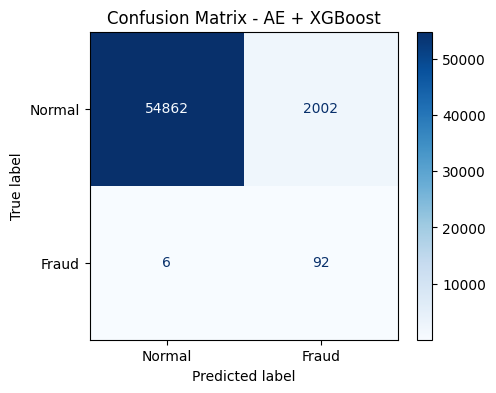

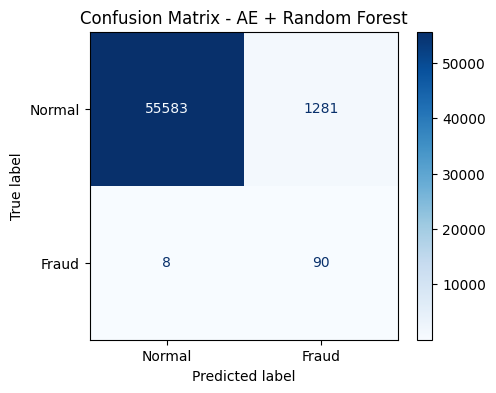

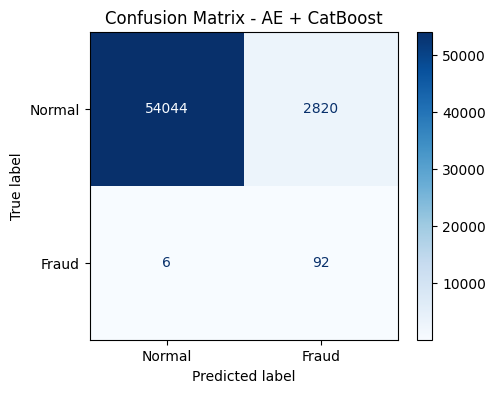

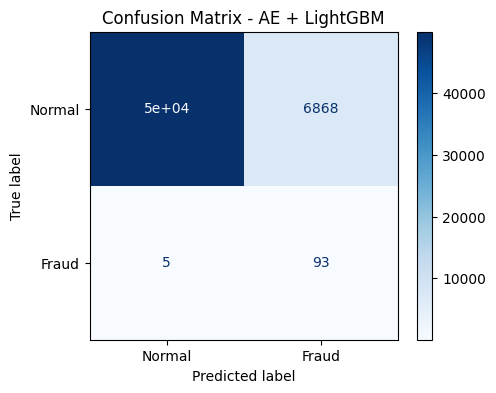

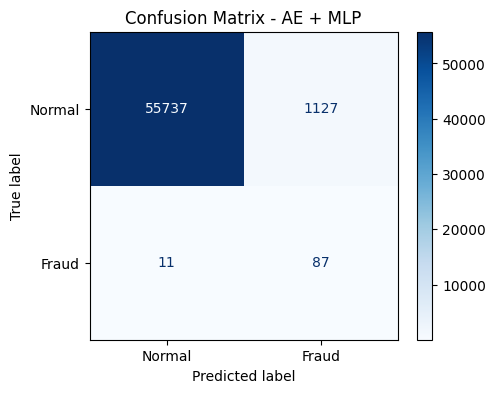

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, data in all_predictions.items():

    pred = data['pred']

    cm = confusion_matrix(y_test_final, pred)

    fig, ax = plt.subplots(figsize=(5,4))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['Normal','Fraud']
    )

    disp.plot(ax=ax, cmap='Blues')

    plt.title(f'Confusion Matrix - {name}')
    plt.show()

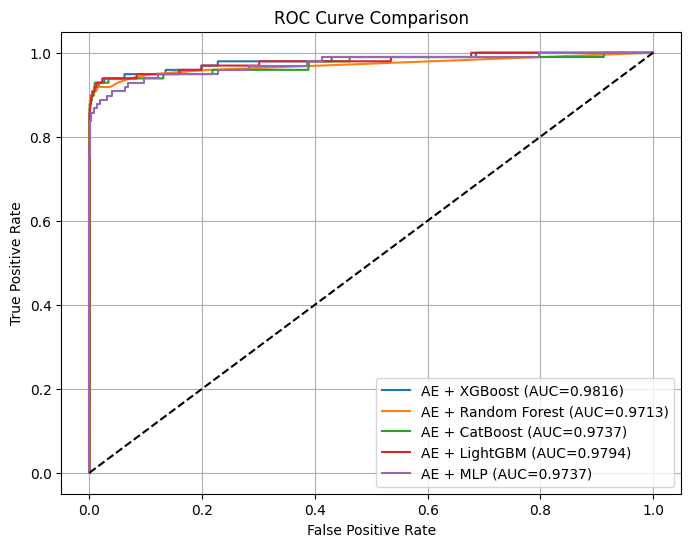

In [21]:
from sklearn.metrics import roc_curve, auc

plt.figure(figsize=(8,6))

for name, data in all_predictions.items():

    prob = data['prob']

    fpr, tpr, _ = roc_curve(y_test_final, prob)

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{name} (AUC={roc_auc:.4f})'
    )

plt.plot([0,1],[0,1],'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid(True)

plt.show()

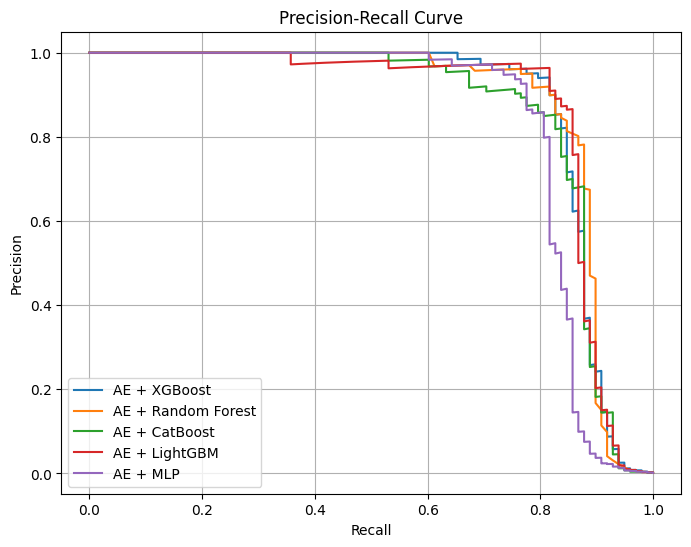

In [22]:
from sklearn.metrics import precision_recall_curve

plt.figure(figsize=(8,6))

for name, data in all_predictions.items():

    prob = data['prob']

    precision, recall, _ = precision_recall_curve(
        y_test_final,
        prob
    )

    plt.plot(
        recall,
        precision,
        label=name
    )

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.grid(True)

plt.show()

In [23]:
for name, data in all_predictions.items():

    pred = data['pred']

    print("\n" + "="*70)
    print(name)
    print("="*70)

    print(
        classification_report(
            y_test_final,
            pred,
            digits=4
        )
    )



AE + XGBoost
              precision    recall  f1-score   support

           0     0.9999    0.9648    0.9820     56864
           1     0.0439    0.9388    0.0839        98

    accuracy                         0.9647     56962
   macro avg     0.5219    0.9518    0.5330     56962
weighted avg     0.9982    0.9647    0.9805     56962


AE + Random Forest
              precision    recall  f1-score   support

           0     0.9999    0.9775    0.9885     56864
           1     0.0656    0.9184    0.1225        98

    accuracy                         0.9774     56962
   macro avg     0.5328    0.9479    0.5555     56962
weighted avg     0.9982    0.9774    0.9870     56962


AE + CatBoost
              precision    recall  f1-score   support

           0     0.9999    0.9504    0.9745     56864
           1     0.0316    0.9388    0.0611        98

    accuracy                         0.9504     56962
   macro avg     0.5157    0.9446    0.5178     56962
weighted avg     0.9982  

In [24]:
summary = []

for name, data in all_predictions.items():

    pred = data['pred']
    prob = data['prob']

    summary.append([
        name,
        accuracy_score(y_test_final,pred)*100,
        precision_score(y_test_final,pred)*100,
        recall_score(y_test_final,pred)*100,
        f1_score(y_test_final,pred)*100,
        roc_auc_score(y_test_final,prob)*100
    ])

result_df = pd.DataFrame(
    summary,
    columns=[
        'Model',
        'Accuracy',
        'Precision',
        'Recall',
        'F1',
        'AUC'
    ]
)

result_df.sort_values(
    by='Recall',
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,AUC
3,AE + LightGBM,87.934061,1.336015,94.897959,2.634934,97.942728
0,AE + XGBoost,96.474843,4.393505,93.877551,8.394161,98.157024
2,AE + CatBoost,95.038798,3.159341,93.877551,6.112957,97.374132
1,AE + Random Forest,97.737088,6.564551,91.836735,12.253233,97.130811
4,AE + MLP,98.002177,7.166392,88.775510,13.262195,97.367152


In [25]:
# Legacy cell safety fix: the previous version appended Precision/F1 to
# bootstrap_results outside the bootstrap loop and could raise a KeyError.
# It is intentionally disabled so the original main pipeline is unchanged.
print('Legacy incomplete bootstrap Precision/F1 append skipped; original bootstrap Acc/Recall/AUC remains unchanged.')


Legacy incomplete bootstrap Precision/F1 append skipped; original bootstrap Acc/Recall/AUC remains unchanged.


# REVIEWER-ONLY EXPERIMENTS — ORIGINAL PIPELINE PRESERVED

**Important:** All cells above this section are the original notebook pipeline. They are not reimplemented or replaced here.

The cells below are **additional reviewer experiments only**. They reuse the same:
- 80/20 outer split (`random_state=42`)
- AutoEncoder architecture and training settings
- Hybrid feature construction
- classifier configurations
- internal Fit/Threshold split
- SMOTE implementation
- Weight-Swept Youden's J implementation

These experiments do **not** overwrite the original `results`, `auc_results`, `best_weight_per_model`, `all_predictions`, or `result_df`.

The purpose is to produce fair comparison tables for:
1. No SMOTE vs Partial/Full SMOTE ratios.
2. Threshold 0.5 vs Weight-Swept Youden's J.
3. Hybrid Feature Representation ablation.
4. Component ablation.

For runtime, reviewer-only experiments default to 3-fold CV. Set `REVIEWER_N_FOLDS = 5` if you want the reviewer experiments to use the same 5-fold protocol as the main pipeline. The original main pipeline is unaffected either way.


In [26]:

# ============================================================
# REVIEWER EXPERIMENT HELPERS — DO NOT MODIFY MAIN PIPELINE
# ============================================================
import gc
import tensorflow as tf
from sklearn.base import clone

REVIEWER_N_FOLDS = 3  # change to 5 for same CV count as main paper
REVIEWER_SMOTE_RATIOS = [None, 0.10, 0.25, 0.50, 1.00]
REVIEWER_WEIGHTS = WEIGHT_CANDIDATES[:]  # [0.60, 0.65, 0.70, 0.75, 0.80]

def reviewer_make_model(name):
    """Exact classifier settings copied from the original main pipeline."""
    if name == 'AE + XGBoost':
        return xgb.XGBClassifier(
            n_estimators=200, learning_rate=0.05, max_depth=6,
            min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
            random_state=42, eval_metric='auc', verbosity=0
        )
    if name == 'AE + Random Forest':
        return RandomForestClassifier(
            n_estimators=200, max_depth=None, n_jobs=-1, random_state=42
        )
    if name == 'AE + CatBoost':
        return CatBoostClassifier(
            iterations=200, learning_rate=0.05, depth=6,
            random_state=42, verbose=0
        )
    if name == 'AE + LightGBM':
        return lgb.LGBMClassifier(
            n_estimators=200, learning_rate=0.05, max_depth=6,
            subsample=0.8, colsample_bytree=0.8,
            is_unbalance=False, random_state=42, verbose=-1
        )
    if name == 'AE + MLP':
        return MLPClassifier(
            hidden_layer_sizes=(256, 128, 64),
            activation='relu', solver='adam',
            learning_rate_init=0.001, max_iter=200,
            early_stopping=True, validation_fraction=0.1,
            random_state=42
        )
    raise ValueError(f'Unknown model: {name}')

def reviewer_fit_smote(X_fit, y_fit, ratio, fold_num):
    """No SMOTE or the exact original apply_smote() implementation."""
    if ratio is None:
        return X_fit, y_fit
    return apply_smote(X_fit, y_fit, fold_num, sampling_strategy=ratio)

def reviewer_metrics(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
    return {
        'Accuracy (%)': accuracy_score(y_true, pred)*100,
        'Precision (%)': precision_score(y_true, pred, zero_division=0)*100,
        'Recall (%)': recall_score(y_true, pred, zero_division=0)*100,
        'F1 (%)': f1_score(y_true, pred, zero_division=0)*100,
        'AUC (%)': roc_auc_score(y_true, prob)*100,
        'FPR (%)': (fp/(fp+tn)*100) if (fp+tn) else 0.0,
        'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn),
        'Threshold': float(threshold)
    }

def reviewer_train_fold_features(train_idx, val_idx):
    """One fold using the original AE/scaler/split logic, once per fold."""
    X_train_raw = X_train_full[train_idx]
    X_val_raw   = X_train_full[val_idx]
    y_train     = y_train_full[train_idx]
    y_val       = y_train_full[val_idx]

    scaler_r = StandardScaler()
    X_train = scaler_r.fit_transform(X_train_raw)
    X_val   = scaler_r.transform(X_val_raw)

    X_train_normal = X_train[y_train == 0]
    ae_r, encoder_r = build_autoencoder(X_train.shape[1])
    ae_r.fit(
        X_train_normal, X_train_normal,
        epochs=50, batch_size=64, validation_split=0.1,
        callbacks=[EarlyStopping(monitor='val_loss', patience=5,
                                 restore_best_weights=True)],
        verbose=0
    )

    X_train_hybrid, X_val_hybrid = extract_hybrid_features(
        ae_r, encoder_r, X_train, X_val
    )

    X_fit, X_thresh, y_fit, y_thresh = train_test_split(
        X_train_hybrid, y_train,
        test_size=0.20, stratify=y_train, random_state=42
    )

    return {
        'X_train': X_train, 'X_val': X_val,
        'y_train': y_train, 'y_val': y_val,
        'X_train_hybrid': X_train_hybrid, 'X_val_hybrid': X_val_hybrid,
        'X_fit': X_fit, 'X_thresh': X_thresh,
        'y_fit': y_fit, 'y_thresh': y_thresh,
        'scaler': scaler_r, 'ae': ae_r, 'encoder': encoder_r
    }


In [27]:

# ============================================================
# REVIEWER EXPERIMENT A — SMOTE / IMBALANCE STRATEGY
# ============================================================
# Comparison: No SMOTE, 0.10, 0.25, 0.50, 1.00
# Same AE representation + same classifier settings.
# Fixed threshold weight = 0.75 so the sampling effect is isolated.
# ============================================================

reviewer_smote_rows = []
reviewer_smote_fold_rows = []

reviewer_skf = StratifiedKFold(
    n_splits=REVIEWER_N_FOLDS, shuffle=True, random_state=42
)

for fold_num, (train_idx, val_idx) in enumerate(
    reviewer_skf.split(X_train_full, y_train_full), start=1
):
    print(f'\n[Reviewer SMOTE] Fold {fold_num}/{REVIEWER_N_FOLDS}')
    pack = reviewer_train_fold_features(train_idx, val_idx)

    for ratio in REVIEWER_SMOTE_RATIOS:
        label = 'No SMOTE' if ratio is None else f'SMOTE {ratio:.2f}'
        X_tr, y_tr = reviewer_fit_smote(
            pack['X_fit'], pack['y_fit'], ratio, fold_num
        )

        for model_name in MODEL_NAMES:
            model = reviewer_make_model(model_name)
            model.fit(X_tr, y_tr)

            # Fixed weight for a controlled SMOTE comparison.
            threshold = find_optimal_threshold(
                model, pack['X_thresh'], pack['y_thresh'], weight=0.75
            )
            prob = model.predict_proba(pack['X_val_hybrid'])[:, 1]
            met = reviewer_metrics(pack['y_val'], prob, threshold)

            row = {
                'Experiment': 'SMOTE Comparison',
                'Fold': fold_num,
                'SMOTE': label,
                'SMOTE Ratio': ratio if ratio is not None else 0.0,
                'Threshold Method': 'Weighted Youden J (fixed w=0.75)',
                'Model': model_name,
                **met
            }
            reviewer_smote_fold_rows.append(row)

    del pack['ae'], pack['encoder']
    tf.keras.backend.clear_session()
    gc.collect()

reviewer_smote_fold_df = pd.DataFrame(reviewer_smote_fold_rows)
reviewer_smote_summary_df = (
    reviewer_smote_fold_df
    .groupby(['SMOTE','SMOTE Ratio','Model'], as_index=False)
    [['Accuracy (%)','Precision (%)','Recall (%)','F1 (%)','AUC (%)','FPR (%)',
      'TP','FP','FN','TN']]
    .mean()
)

print('\n=== REVIEWER SMOTE COMPARISON ===')
display(reviewer_smote_summary_df.sort_values(['Model','SMOTE Ratio']))



[Reviewer SMOTE] Fold 1/3
[Fold 1] SMOTE (sampling_strategy=0.1): fraud 210 → 12130 | normal tetap 121306 | total train 121516 → 133436
[Fold 1] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121306 | total train 121516 → 151632
[Fold 1] SMOTE (sampling_strategy=0.5): fraud 210 → 60653 | normal tetap 121306 | total train 121516 → 181959
[Fold 1] SMOTE (sampling_strategy=1.0): fraud 210 → 121306 | normal tetap 121306 | total train 121516 → 242612

[Reviewer SMOTE] Fold 2/3
[Fold 2] SMOTE (sampling_strategy=0.1): fraud 210 → 12130 | normal tetap 121307 | total train 121517 → 133437
[Fold 2] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121307 | total train 121517 → 151633
[Fold 2] SMOTE (sampling_strategy=0.5): fraud 210 → 60653 | normal tetap 121307 | total train 121517 → 181960
[Fold 2] SMOTE (sampling_strategy=1.0): fraud 210 → 121307 | normal tetap 121307 | total train 121517 → 242614

[Reviewer SMOTE] Fold 3/3
[Fold 3] SMOTE (sampling_strategy=0

,SMOTE,SMOTE Ratio,Model,Accuracy (%),Precision (%),Recall (%),F1 (%),AUC (%),FPR (%),TP,FP,FN,TN
0,No SMOTE,0.00,AE + CatBoost,83.842926,1.255414,95.944175,2.470713,98.069808,16.177990,126.000000,12265.666667,5.333333,63551.333333
5,SMOTE 0.10,0.10,AE + CatBoost,84.614045,2.577215,94.679621,4.890599,97.858073,15.403318,124.333333,11678.333333,7.000000,64138.666667
10,SMOTE 0.25,0.25,AE + CatBoost,88.539989,1.771264,93.912407,3.461134,97.856828,11.469283,123.333333,8695.666667,8.000000,67121.333333
15,SMOTE 0.50,0.50,AE + CatBoost,87.290903,1.525265,93.657954,2.994710,97.815565,12.720102,123.000000,9644.000000,8.333333,66173.000000
20,SMOTE 1.00,1.00,AE + CatBoost,86.815146,1.266658,94.671910,2.498680,97.829990,13.198447,124.333333,10006.666667,7.000000,65810.333333
1,No SMOTE,0.00,AE + LightGBM,89.589821,2.108671,85.806539,4.061031,90.900209,10.403559,112.666667,7887.666667,18.666667,67929.333333
6,SMOTE 0.10,0.10,AE + LightGBM,87.168001,1.571145,94.926363,3.078193,97.715935,12.845404,124.666667,9739.000000,6.666667,66078.000000
11,SMOTE 0.25,0.25,AE + LightGBM,90.644040,7.767620,92.649780,12.857588,97.544202,9.359379,121.666667,7096.000000,9.666667,68721.000000
16,SMOTE 0.50,0.50,AE + LightGBM,85.039332,3.701119,93.922045,6.771943,97.557849,14.975973,123.333333,11354.333333,8.000000,64462.666667
21,SMOTE 1.00,1.00,AE + LightGBM,84.174311,1.235986,96.192844,2.436573,97.751116,15.846490,126.333333,12014.333333,5.000000,63802.666667


In [28]:

# ============================================================
# REVIEWER EXPERIMENT B — THRESHOLD ABLATION
# ============================================================
# Same Hybrid + Partial SMOTE(0.25) model:
#   1) fixed threshold 0.50
#   2) Weight-Swept Youden's J, w in [0.60..0.80]
# No retraining between thresholds.
# ============================================================

reviewer_threshold_rows = []
reviewer_threshold_fold_rows = []

for fold_num, (train_idx, val_idx) in enumerate(
    reviewer_skf.split(X_train_full, y_train_full), start=1
):
    print(f'\n[Reviewer Threshold] Fold {fold_num}/{REVIEWER_N_FOLDS}')
    pack = reviewer_train_fold_features(train_idx, val_idx)

    X_tr, y_tr = reviewer_fit_smote(
        pack['X_fit'], pack['y_fit'], 0.25, fold_num
    )

    for model_name in MODEL_NAMES:
        model = reviewer_make_model(model_name)
        model.fit(X_tr, y_tr)

        prob_tune = model.predict_proba(pack['X_thresh'])[:, 1]
        fpr_t, tpr_t, thresholds_t = roc_curve(
            pack['y_thresh'], prob_tune
        )

        # Default threshold
        prob_val = model.predict_proba(pack['X_val_hybrid'])[:, 1]
        met_default = reviewer_metrics(pack['y_val'], prob_val, 0.50)
        reviewer_threshold_fold_rows.append({
            'Experiment': 'Threshold Ablation',
            'Fold': fold_num,
            'Model': model_name,
            'Method': 'Default threshold',
            'Weight': np.nan,
            **met_default
        })

        # Weight sweep: select weight by tuning-set F1, matching the
        # main notebook's principle of selecting a weight before validation.
        candidate_rows = []
        for w in REVIEWER_WEIGHTS:
            j = (w * tpr_t) - ((1-w) * fpr_t)
            t = thresholds_t[np.argmax(j)]
            pred_tune = (prob_tune >= t).astype(int)
            candidate_rows.append({
                'Weight': w,
                'Threshold': t,
                'Tuning F1 (%)': f1_score(
                    pack['y_thresh'], pred_tune, zero_division=0
                ) * 100
            })

        candidate_df = pd.DataFrame(candidate_rows)
        best_row = candidate_df.sort_values(
            ['Tuning F1 (%)','Weight'], ascending=[False, True]
        ).iloc[0]

        met_ws = reviewer_metrics(
            pack['y_val'], prob_val, float(best_row['Threshold'])
        )
        reviewer_threshold_fold_rows.append({
            'Experiment': 'Threshold Ablation',
            'Fold': fold_num,
            'Model': model_name,
            'Method': "Weight-Swept Youden's J",
            'Weight': float(best_row['Weight']),
            'Tuning F1 (%)': float(best_row['Tuning F1 (%)']),
            **met_ws
        })

        reviewer_threshold_rows.extend([
            {
                'Fold': fold_num, 'Model': model_name,
                'Weight': float(r['Weight']),
                'Threshold': float(r['Threshold']),
                'Tuning F1 (%)': float(r['Tuning F1 (%)'])
            } for r in candidate_rows
        ])

    del pack['ae'], pack['encoder']
    tf.keras.backend.clear_session()
    gc.collect()

reviewer_threshold_fold_df = pd.DataFrame(reviewer_threshold_fold_rows)
reviewer_threshold_summary_df = (
    reviewer_threshold_fold_df
    .groupby(['Model','Method'], as_index=False)
    [['Accuracy (%)','Precision (%)','Recall (%)','F1 (%)','AUC (%)','FPR (%)',
      'TP','FP','FN','TN']]
    .mean()
)
reviewer_weight_sweep_df = pd.DataFrame(reviewer_threshold_rows)

print('\n=== REVIEWER THRESHOLD ABLATION ===')
display(reviewer_threshold_summary_df)
print('\n=== WEIGHT SWEEP DETAILS ===')
display(reviewer_weight_sweep_df)



[Reviewer Threshold] Fold 1/3
[Fold 1] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121306 | total train 121516 → 151632

[Reviewer Threshold] Fold 2/3
[Fold 2] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121307 | total train 121517 → 151633

[Reviewer Threshold] Fold 3/3
[Fold 3] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121307 | total train 121517 → 151633

=== REVIEWER THRESHOLD ABLATION ===


,Model,Method,Accuracy (%),Precision (%),Recall (%),F1 (%),AUC (%),FPR (%),TP,FP,FN,TN
0,AE + CatBoost,Default threshold,99.902565,68.146729,82.997918,74.694836,97.353320,0.068147,109.000000,51.666667,22.333333,75765.333333
1,AE + CatBoost,Weight-Swept Youden's J,95.144046,31.086011,87.583854,30.784971,97.353320,4.842801,115.000000,3671.666667,16.333333,72145.333333
2,AE + LightGBM,Default threshold,99.920999,74.923415,81.982034,78.201572,97.420135,0.047922,107.666667,36.333333,23.666667,75780.666667
3,AE + LightGBM,Weight-Swept Youden's J,96.193892,6.174049,89.345748,11.246282,97.420135,3.794224,117.333333,2876.666667,14.000000,72940.333333
4,AE + MLP,Default threshold,99.915293,73.673596,79.447143,76.448833,95.330260,0.049241,104.333333,37.333333,27.000000,75779.666667
5,AE + MLP,Weight-Swept Youden's J,94.639754,21.177012,85.804611,25.253519,95.330260,5.344887,112.666667,4052.333333,18.666667,71764.666667
6,AE + Random Forest,Default threshold,99.945577,87.367521,80.206647,83.580738,97.374812,0.020224,105.333333,15.333333,26.000000,75801.666667
7,AE + Random Forest,Weight-Swept Youden's J,98.383111,10.794129,90.604518,18.925909,97.374812,1.603422,119.000000,1215.666667,12.333333,74601.333333
8,AE + XGBoost,Default threshold,99.913538,71.929295,82.997918,76.908094,97.731987,0.057155,109.000000,43.333333,22.333333,75773.666667
9,AE + XGBoost,Weight-Swept Youden's J,95.752366,4.716465,91.874855,8.892075,97.731987,4.240913,120.666667,3215.333333,10.666667,72601.666667



=== WEIGHT SWEEP DETAILS ===


,Fold,Model,Weight,Threshold,Tuning F1 (%)
0,1,AE + XGBoost,0.60,8.999924e-03,11.822660
1,1,AE + XGBoost,0.65,8.999924e-03,11.822660
2,1,AE + XGBoost,0.70,8.999924e-03,11.822660
3,1,AE + XGBoost,0.75,1.915406e-03,4.147270
4,1,AE + XGBoost,0.80,1.915406e-03,4.147270
...,...,...,...,...,...
70,3,AE + MLP,0.60,8.942731e-09,5.153509
71,3,AE + MLP,0.65,8.942731e-09,5.153509
72,3,AE + MLP,0.70,8.942731e-09,5.153509
73,3,AE + MLP,0.75,8.942731e-09,5.153509


In [29]:

# ============================================================
# REVIEWER EXPERIMENT C — FEATURE REPRESENTATION ABLATION
# ============================================================
# All 5 classifiers (not just AE + MLP).
# Same fold, same AE, same internal split.
# Feature sets:
#   Original (29)
#   AE Latent (256)
#   Original + AE Latent (285)
#   Hybrid + Reconstruction Error (286)
#
# Partial SMOTE(0.25) is kept fixed to isolate feature contribution.
# Threshold = 0.50 is used here so this table is easy to interpret.
# The fit/threshold-tuning split and SMOTE are computed ONCE per
# feature set per fold, then reused across all 5 classifiers so the
# comparison across models is on identical data.
# ============================================================

reviewer_feature_fold_rows = []

for fold_num, (train_idx, val_idx) in enumerate(
    reviewer_skf.split(X_train_full, y_train_full), start=1
):
    print(f'\n[Reviewer Feature] Fold {fold_num}/{REVIEWER_N_FOLDS}')
    pack = reviewer_train_fold_features(train_idx, val_idx)

    X_train_sc = pack['X_train']
    X_val_sc   = pack['X_val']
    X_train_h  = pack['X_train_hybrid']
    X_val_h    = pack['X_val_hybrid']

    # Reconstruct latent and reconstruction-error components exactly
    # as produced by the original helper.
    lat_train = pack['encoder'].predict(X_train_sc, verbose=0)
    lat_val   = pack['encoder'].predict(X_val_sc, verbose=0)
    rec_train = np.mean(
        np.power(X_train_sc - pack['ae'].predict(X_train_sc, verbose=0), 2),
        axis=1, keepdims=True
    )
    rec_val = np.mean(
        np.power(X_val_sc - pack['ae'].predict(X_val_sc, verbose=0), 2),
        axis=1, keepdims=True
    )

    feature_sets = {
        'Original (29)': (X_train_sc, X_val_sc),
        'AE Latent (256)': (lat_train, lat_val),
        'Original + AE Latent (285)': (
            np.hstack((X_train_sc, lat_train)),
            np.hstack((X_val_sc, lat_val))
        ),
        'Hybrid + Reconstruction Error (286)': (X_train_h, X_val_h)
    }

    for feature_name, (Xf_train, Xf_val) in feature_sets.items():
        X_fit_f, X_thresh_f, y_fit_f, y_thresh_f = train_test_split(
            Xf_train, pack['y_train'],
            test_size=0.20, stratify=pack['y_train'], random_state=42
        )
        X_tr_f, y_tr_f = reviewer_fit_smote(
            X_fit_f, y_fit_f, 0.25, fold_num
        )

        for model_name in MODEL_NAMES:
            model = reviewer_make_model(model_name)
            model.fit(X_tr_f, y_tr_f)

            prob = model.predict_proba(Xf_val)[:, 1]
            met = reviewer_metrics(pack['y_val'], prob, 0.50)

            reviewer_feature_fold_rows.append({
                'Experiment': 'Feature Ablation',
                'Fold': fold_num,
                'Feature Set': feature_name,
                'Model': model_name,
                **met
            })

    del pack['ae'], pack['encoder']
    tf.keras.backend.clear_session()
    gc.collect()

reviewer_feature_fold_df = pd.DataFrame(reviewer_feature_fold_rows)
reviewer_feature_summary_df = (
    reviewer_feature_fold_df
    .groupby(['Feature Set', 'Model'], as_index=False)
    [['Accuracy (%)','Precision (%)','Recall (%)','F1 (%)','AUC (%)','FPR (%)',
      'TP','FP','FN','TN']]
    .mean()
)

print('\n=== REVIEWER FEATURE ABLATION (ALL 5 MODELS) ===')
display(reviewer_feature_summary_df.sort_values(['Model','Feature Set']))



[Reviewer Feature] Fold 1/3
[Fold 1] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121306 | total train 121516 → 151632
[Fold 1] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121306 | total train 121516 → 151632
[Fold 1] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121306 | total train 121516 → 151632
[Fold 1] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121306 | total train 121516 → 151632

[Reviewer Feature] Fold 2/3
[Fold 2] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121307 | total train 121517 → 151633
[Fold 2] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121307 | total train 121517 → 151633
[Fold 2] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121307 | total train 121517 → 151633
[Fold 2] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121307 | total train 121517 → 151633

[Reviewer Feature] Fold 3/3
[Fold 3] SMOTE (sampling_

,Feature Set,Model,Accuracy (%),Precision (%),Recall (%),F1 (%),AUC (%),FPR (%),TP,FP,FN,TN
0,AE Latent (256),AE + CatBoost,99.887643,63.313856,84.266327,72.209776,97.548250,0.085293,110.666667,64.666667,20.666667,75752.333333
5,Hybrid + Reconstruction Error (286),AE + CatBoost,99.892032,64.940330,82.745393,72.643919,97.794847,0.078259,108.666667,59.333333,22.666667,75757.666667
10,Original (29),AE + CatBoost,99.867893,58.521713,82.745393,68.441486,97.671306,0.102440,108.666667,77.666667,22.666667,75739.333333
15,Original + AE Latent (285),AE + CatBoost,99.900371,67.436605,82.745393,74.198943,97.967065,0.069905,108.666667,53.000000,22.666667,75764.000000
1,AE Latent (256),AE + LightGBM,99.913099,72.040299,81.725653,76.508660,97.547671,0.055397,107.333333,42.000000,24.000000,75775.000000
6,Hybrid + Reconstruction Error (286),AE + LightGBM,99.920560,75.141891,80.970005,77.890424,97.839345,0.046603,106.333333,35.333333,25.000000,75781.666667
11,Original (29),AE + LightGBM,99.895543,66.097348,81.733364,73.014808,97.480939,0.072983,107.333333,55.333333,24.000000,75761.666667
16,Original + AE Latent (285),AE + LightGBM,99.922755,76.346991,80.208574,78.202040,97.722701,0.043086,105.333333,32.666667,26.000000,75784.333333
2,AE Latent (256),AE + MLP,99.856920,56.948780,82.489012,67.062829,95.601474,0.112991,108.333333,85.666667,23.000000,75731.333333
7,Hybrid + Reconstruction Error (286),AE + MLP,99.922755,77.276350,79.190763,78.108296,95.351665,0.041328,104.000000,31.333333,27.333333,75785.666667


In [30]:

# ============================================================
# REVIEWER EXPERIMENT D — COMPONENT ABLATION
# ============================================================
# All 5 classifiers (not just AE + MLP).
# This directly measures:
#   A. Original + No SMOTE + threshold 0.50
#   B. Hybrid + No SMOTE + threshold 0.50
#   C. Hybrid + SMOTE 0.25 + threshold 0.50
#   D. Hybrid + SMOTE 0.25 + Weight-Swept Youden's J
#
# The AE is trained ONCE per fold (shared across configs and models).
# Only the classifier fit is repeated per configuration per model.
# This is an additional experiment only; original pipeline is untouched.
# ============================================================

reviewer_component_fold_rows = []

for fold_num, (train_idx, val_idx) in enumerate(
    reviewer_skf.split(X_train_full, y_train_full), start=1
):
    print(f'\n[Reviewer Component] Fold {fold_num}/{REVIEWER_N_FOLDS}')
    pack = reviewer_train_fold_features(train_idx, val_idx)

    # Build Original and Hybrid representations.
    X_orig_train = pack['X_train']
    X_orig_val   = pack['X_val']
    X_hyb_train  = pack['X_train_hybrid']
    X_hyb_val    = pack['X_val_hybrid']

    configurations = {
        'A. Original + No SMOTE + Threshold 0.50':
            (X_orig_train, X_orig_val, None, 'default'),
        'B. Hybrid + No SMOTE + Threshold 0.50':
            (X_hyb_train, X_hyb_val, None, 'default'),
        'C. Hybrid + SMOTE 0.25 + Threshold 0.50':
            (X_hyb_train, X_hyb_val, 0.25, 'default'),
        'D. Hybrid + SMOTE 0.25 + Weight-Swept Youden J':
            (X_hyb_train, X_hyb_val, 0.25, 'weighted')
    }

    for config_name, (Xcfg_train, Xcfg_val, ratio, threshold_mode) in configurations.items():
        X_fit_c, X_thresh_c, y_fit_c, y_thresh_c = train_test_split(
            Xcfg_train, pack['y_train'],
            test_size=0.20, stratify=pack['y_train'], random_state=42
        )
        X_tr_c, y_tr_c = reviewer_fit_smote(
            X_fit_c, y_fit_c, ratio, fold_num
        )

        for model_name in MODEL_NAMES:          # <-- loop tambahan: semua 5 model
            model = reviewer_make_model(model_name)
            model.fit(X_tr_c, y_tr_c)

            prob_tune = model.predict_proba(X_thresh_c)[:, 1]
            prob_val = model.predict_proba(Xcfg_val)[:, 1]

            if threshold_mode == 'default':
                selected_threshold = 0.50
                selected_weight = np.nan
                tuning_f1 = np.nan
            else:
                fpr_t, tpr_t, thresholds_t = roc_curve(y_thresh_c, prob_tune)
                candidates = []
                for w in REVIEWER_WEIGHTS:
                    j = (w*tpr_t) - ((1-w)*fpr_t)
                    t = thresholds_t[np.argmax(j)]
                    pred_t = (prob_tune >= t).astype(int)
                    candidates.append((
                        f1_score(y_thresh_c, pred_t, zero_division=0),
                        w, t
                    ))
                tuning_f1, selected_weight, selected_threshold = max(
                    candidates, key=lambda z: (z[0], -z[1])
                )
                tuning_f1 *= 100

            met = reviewer_metrics(
                pack['y_val'], prob_val, float(selected_threshold)
            )
            reviewer_component_fold_rows.append({
                'Experiment': 'Component Ablation',
                'Fold': fold_num,
                'Configuration': config_name,
                'Model': model_name,             # <-- kolom baru
                'Weight': selected_weight,
                'Tuning F1 (%)': tuning_f1,
                **met
            })

    del pack['ae'], pack['encoder']
    tf.keras.backend.clear_session()
    gc.collect()

reviewer_component_fold_df = pd.DataFrame(reviewer_component_fold_rows)
reviewer_component_summary_df = (
    reviewer_component_fold_df
    .groupby(['Configuration', 'Model'], as_index=False)   # <-- tambah 'Model'
    [['Accuracy (%)','Precision (%)','Recall (%)','F1 (%)','AUC (%)','FPR (%)',
      'TP','FP','FN','TN']]
    .mean()
)

print('\n=== REVIEWER COMPONENT ABLATION (ALL 5 MODELS) ===')
display(reviewer_component_summary_df.sort_values(['Model','Configuration']))



[Reviewer Component] Fold 1/3
[Fold 1] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121306 | total train 121516 → 151632
[Fold 1] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121306 | total train 121516 → 151632

[Reviewer Component] Fold 2/3
[Fold 2] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121307 | total train 121517 → 151633
[Fold 2] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121307 | total train 121517 → 151633

[Reviewer Component] Fold 3/3
[Fold 3] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121307 | total train 121517 → 151633
[Fold 3] SMOTE (sampling_strategy=0.25): fraud 210 → 30326 | normal tetap 121307 | total train 121517 → 151633

=== REVIEWER COMPONENT ABLATION (ALL 5 MODELS) ===


,Configuration,Model,Accuracy (%),Precision (%),Recall (%),F1 (%),AUC (%),FPR (%),TP,FP,FN,TN
0,A. Original + No SMOTE + Threshold 0.50,AE + CatBoost,99.953916,94.504185,77.922353,85.383622,97.798734,0.007914,102.333333,6.000000,29.000000,75811.000000
5,B. Hybrid + No SMOTE + Threshold 0.50,AE + CatBoost,99.951283,93.614392,77.164778,84.531212,97.624437,0.009233,101.333333,7.000000,30.000000,75810.000000
10,C. Hybrid + SMOTE 0.25 + Threshold 0.50,AE + CatBoost,99.899054,66.916326,84.264400,74.394700,97.321080,0.073862,110.666667,56.000000,20.666667,75761.000000
15,D. Hybrid + SMOTE 0.25 + Weight-Swept Youden J,AE + CatBoost,96.320299,5.435200,90.864754,10.151120,97.321080,3.670241,119.333333,2782.666667,12.000000,73034.333333
1,A. Original + No SMOTE + Threshold 0.50,AE + LightGBM,99.782308,48.860932,68.262780,54.903406,84.585582,0.163112,89.666667,123.666667,41.666667,75693.333333
6,B. Hybrid + No SMOTE + Threshold 0.50,AE + LightGBM,99.817860,63.852670,70.830442,64.132782,88.439841,0.131897,93.000000,100.000000,38.333333,75717.000000
11,C. Hybrid + SMOTE 0.25 + Threshold 0.50,AE + LightGBM,99.928899,77.814234,82.489012,80.055918,97.022210,0.040888,108.333333,31.000000,23.000000,75786.000000
16,D. Hybrid + SMOTE 0.25 + Weight-Swept Youden J,AE + LightGBM,97.048425,6.753949,90.862827,12.390449,97.022210,2.940853,119.333333,2229.666667,12.000000,73587.333333
2,A. Original + No SMOTE + Threshold 0.50,AE + MLP,99.942944,86.138002,79.952194,82.896086,96.313214,0.022422,105.000000,17.000000,26.333333,75800.000000
7,B. Hybrid + No SMOTE + Threshold 0.50,AE + MLP,99.947333,90.690144,77.669828,83.603269,96.390205,0.014069,102.000000,10.666667,29.333333,75806.333333


In [31]:

# ============================================================
# REFERENCE ONLY — TABLE VII SOTA / BASELINE VALUES FROM THE PAPER
# ============================================================
# These values are NOT used for tuning, model selection, or threshold selection.
# They are included only for later comparison with the reviewer experiments.

sota_reference_df = pd.DataFrame([
    ['Autoencoder + RBCE + SMOTE [Sulaiman et al.]', 95.13, 3.12, 91.17, 6.04, 93.15],
    ['Autoencoder (Anomaly-Based) [Nata et al.]', 94.98, 3.00, 85.00, 5.00, 93.13],
    ['AE+CatBoost (Proposed)', 93.88, 2.60, 94.90, 5.07, 97.90],
    ['AE+LightGBM (Proposed)', 97.31, 5.63, 92.86, 10.62, 97.69],
    ['AE+RF (Proposed)', 97.14, 5.26, 91.84, 9.95, 97.74],
    ['AE+XGBoost (Proposed)', 98.49, 9.46, 90.82, 17.13, 97.74],
    ['AE+MLP (Proposed)', 99.09, 14.55, 87.76, 24.96, 97.69],
], columns=['Method','Accuracy (%)','Precision (%)','Recall (%)','F1 (%)','AUC (%)'])

display(sota_reference_df)


,Method,Accuracy (%),Precision (%),Recall (%),F1 (%),AUC (%)
0,Autoencoder + RBCE + SMOTE [Sulaiman et al.],95.13,3.12,91.17,6.04,93.15
1,Autoencoder (Anomaly-Based) [Nata et al.],94.98,3.00,85.00,5.00,93.13
2,AE+CatBoost (Proposed),93.88,2.60,94.90,5.07,97.90
3,AE+LightGBM (Proposed),97.31,5.63,92.86,10.62,97.69
4,AE+RF (Proposed),97.14,5.26,91.84,9.95,97.74
5,AE+XGBoost (Proposed),98.49,9.46,90.82,17.13,97.74
6,AE+MLP (Proposed),99.09,14.55,87.76,24.96,97.69


In [32]:
import os

# ============================================================
# REVIEWER RESULTS EXPORT
# ============================================================
# These files are additional outputs only. Original paper results
# and original variables are not overwritten.
# ============================================================

output_dir = '/kaggle/working'
exports = {
    'reviewer_smote_fold_results.csv': reviewer_smote_fold_df,
    'reviewer_smote_summary.csv': reviewer_smote_summary_df,
    'reviewer_threshold_fold_results.csv': reviewer_threshold_fold_df,
    'reviewer_threshold_summary.csv': reviewer_threshold_summary_df,
    'reviewer_weight_sweep.csv': reviewer_weight_sweep_df,
    'reviewer_feature_ablation_fold_results.csv': reviewer_feature_fold_df,
    'reviewer_feature_ablation_summary.csv': reviewer_feature_summary_df,
    'reviewer_component_ablation_fold_results.csv': reviewer_component_fold_df,
    'reviewer_component_ablation_summary.csv': reviewer_component_summary_df,
}

for filename, data in exports.items():
    data.to_csv(f'{output_dir}/{filename}', index=False)

excel_path = f'{output_dir}/reviewer_comparisons_original_pipeline.xlsx'
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    # Original main result is included only as a reference snapshot.
    sota_reference_df.to_excel(writer, sheet_name='SOTA_Table_VII', index=False)
    if 'result_df' in globals():
        result_df.to_excel(writer, sheet_name='Original_Main_Result', index=False)
    if 'summary_df' in globals():
        summary_df.to_excel(writer, sheet_name='Original_SMOTE_Sensitivity', index=False)
    reviewer_smote_summary_df.to_excel(writer, sheet_name='Reviewer_SMOTE', index=False)
    reviewer_threshold_summary_df.to_excel(writer, sheet_name='Reviewer_Threshold', index=False)
    reviewer_weight_sweep_df.to_excel(writer, sheet_name='Weight_Sweep', index=False)
    reviewer_feature_summary_df.to_excel(writer, sheet_name='Feature_Ablation', index=False)
    reviewer_component_summary_df.to_excel(writer, sheet_name='Component_Ablation', index=False)

print('\n=== REVIEWER EXPERIMENT FILES ===')
for filename in list(exports.keys()) + ['reviewer_comparisons_original_pipeline.xlsx']:
    path = f'{output_dir}/{filename}'
    print(f'{filename}: {os.path.getsize(path)/1024:.1f} KB' if os.path.exists(path) else f'MISSING: {filename}')

print('\nSelesai. Semua hasil reviewer tersimpan tanpa mengganti hasil pipeline utama.')



=== REVIEWER EXPERIMENT FILES ===
reviewer_smote_fold_results.csv: 16.7 KB
reviewer_smote_summary.csv: 4.9 KB
reviewer_threshold_fold_results.csv: 6.1 KB
reviewer_threshold_summary.csv: 2.1 KB
reviewer_weight_sweep.csv: 4.2 KB
reviewer_feature_ablation_fold_results.csv: 10.9 KB
reviewer_feature_ablation_summary.csv: 4.1 KB
reviewer_component_ablation_fold_results.csv: 12.8 KB
reviewer_component_ablation_summary.csv: 4.4 KB
reviewer_comparisons_original_pipeline.xlsx: 21.7 KB

Selesai. Semua hasil reviewer tersimpan tanpa mengganti hasil pipeline utama.
